# Assumptions of Linear Regression

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
from prettytable import PrettyTable

import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

In [2]:
RANDOM_STATE = 42

# Configure NumPy.
rng = np.random.default_rng(seed=RANDOM_STATE)
np.set_printoptions(linewidth=100)

# Configure Seaborn.
sns.set_style("whitegrid")
sns.set_palette("deep")

## 1 Introduction

### 1.1 Generalization

#### Generalization in Linear Regression

- Generalization is one of the most important attribute of ML algorithm.
- During the training process, say an ML model attains good predictive performance on training data.
- A well generalized model must demonstrates the same level of predictive power on **unseen data**.
- **Model diagnostics** help us investigate whether a model is learning appropriately and identify problems that may prevent it from generalizing well.

### 1.2 Model Diagnostic

#### Assumptions of Linear Regression

1. Assumption of Linearity
2. No Multicollinearity
3. No Heteroscedasticity (Homoscedasticity)
4. No Autocorrelation
5. Normality of Residuals

#### Overview

<div style="display: inline-block">

|   # | Assumption              | Variables involved                                                        |
| --: | :---------------------- | :------------------------------------------------------------------------ |
|   1 | Assumption of Linearity | Between Independent variables $X$ and Target variable $y$                 |
|   2 | No Multicollinearity    | Among Independent variables $X$                                           |
|   3 | No Heteroscedasticity   | Between Residuals $(y\,-\,\hat{y})$ and Predicted Target values $\hat{y}$ |
|   4 | No Autocorrelation      | Between Residuals $(y\,-\,\hat{y})$ and Actual Target values $y$          |
|   5 | Normality of Residuals  | Distribution of Residuals $(y\,-\,\hat{y})$                               |

</div>

### 1.3 Dummy Dataset

#### Features and Target Variables

In [3]:
# 100 rows 3 columns.
n, d = 100, 3

# Generate empty feature matrix of zeros.
X = np.zeros(shape=(n, d), dtype=float)

# Add features (with some random noise) to features matrix.
X[:, 0] = rng.normal(0, 1, size=n) + rng.random(n)
X[:, 1] = rng.exponential(1, size=n) + rng.random(n)
X[:, 2] = rng.uniform(0, 2, size=n) + rng.random(n)

# Generate random Target values.
y = 5 * X[:, 0] + 9 * X[:, 1] - 7 * X[:, 2]

#### Visualize dummy dataset

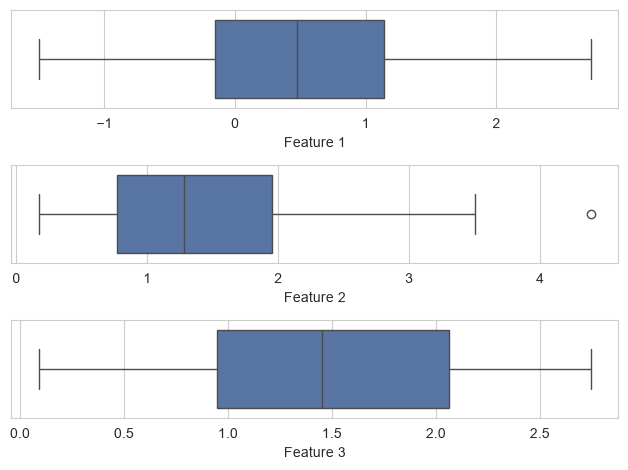

In [4]:
for col_idx in range(d):
    plt.subplot(3, 1, col_idx + 1)
    sns.boxplot(x=X[:, col_idx])
    plt.xlabel(f"Feature {col_idx + 1}")

plt.tight_layout()
plt.show()

## 2 Assumption of Linearity

### 2.1 Introduction

#### What is assumption of Linearity?

- A Linear Regression model will be effective only when there are **Linear relation b/w independent & dependent variable**.
- We start with an assumption that there is linearity b/w independent & dependent variable and verify it using some tests.

### 2.2 Tests for Assumption of Linearity

#### Analytical Tests

1. Pearson Correlation

#### Graphical Tests

1. Scatter Plot
2. Regression Plot
3. Pair Plot

### 2.3 Example

#### Graphical Tests

##### Regression Plot

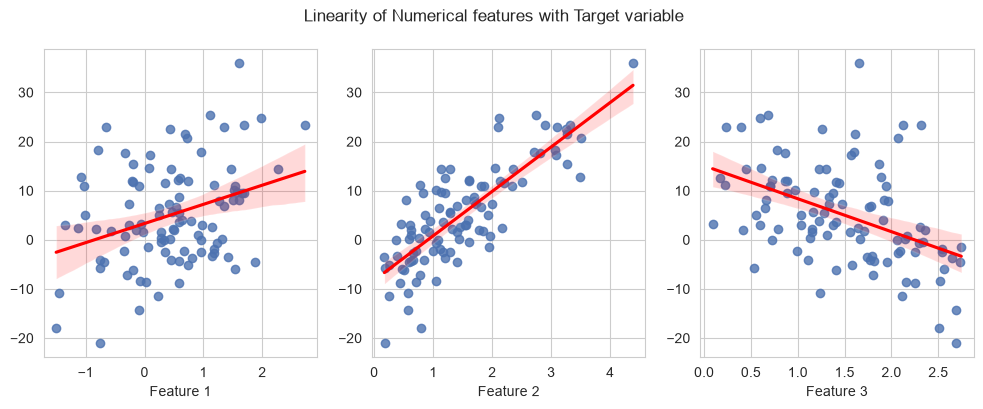

In [5]:
plt.figure(figsize=(12, 4))
plt.suptitle("Linearity of Numerical features with Target variable")

for col_idx in range(d):
    plt.subplot(1, 3, col_idx + 1)
    sns.regplot(x=X[:, col_idx], y=y, line_kws={"color": "red"})
    plt.xlabel(f"Feature {col_idx + 1}")

plt.show()

## 3 No Multicollinearity

### 3.1 Introduction

#### What is Multicollinearity?

- Multicollinearity is when two or more input variables (features) are strongly correlated with each other.
- "No Multicollinearity" is when input variables are **truely independent of one another**.
- The desired nature is **No Multicollinearity** among features in the dataset.

#### Why Multicollinearity is a problem?

- Highly correlated features can lead to **misinterpretation feature importance**.
- When two or more **features are correlated** the model might **distribute the effect** between them in unstable ways.
- For example if features $x_1$ and $x_2$ are highly correlated then model coefficients cannot be trusted as feature importance:
   - $\hat{y}\;=\;0.8\,x_1\;+\;0.2\,x_2$ or
   - $\hat{y}\;=\;0.6\,x_1\;+\;0.4\,x_2$

#### How to resolve Multicollinearity?

### 3.2 Tests for Multicollinearity

#### Analytical Tests

1. Variance Inflation Factor (VIF)

### 3.3 Variance Inflation Factor

$$
\large
\mathrm{VIF}\;=\;\frac{1}{1\;-\;R_j^2}
$$

Where,

- $R_j^2$ is the Ordinary R-squared value of a particular, say $j^{\text{th}}$, independent variable and not the whole model.

#### API

In [6]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

#### Properties

VIF falls in the range $[1,\,\infty)$

In [7]:
# Example R-squared scores:
r2_scores = [-1_000, -100, -10, -1, -0.9, -0.5, -0.01, 0, 0.01, 0.5, 0.8, 0.9, 1]

for r2 in r2_scores:
    vif = "infty" if r2 == 1 else f"{1 / (1 - r2):.2f}"
    print(f"R-squared: {r2:>5} | VIF: {vif:>5}")

R-squared: -1000 | VIF:  0.00
R-squared:  -100 | VIF:  0.01
R-squared:   -10 | VIF:  0.09
R-squared:    -1 | VIF:  0.50
R-squared:  -0.9 | VIF:  0.53
R-squared:  -0.5 | VIF:  0.67
R-squared: -0.01 | VIF:  0.99
R-squared:     0 | VIF:  1.00
R-squared:  0.01 | VIF:  1.01
R-squared:   0.5 | VIF:  2.00
R-squared:   0.8 | VIF:  5.00
R-squared:   0.9 | VIF: 10.00
R-squared:     1 | VIF: infty


### 3.4 Resolve Multicollinearity

#### Code to calculate VIF

In [8]:
from statsmodels.stats.outliers_influence import variance_inflation_factor as VIF


def get_vif_ledger(df):
    """
    Function to compute Variance Inflation Factor (VIF).
    """
    _df = sm.add_constant(df)

    # Compute VIF for each feature.
    vif_ledger = [[f_name, VIF(_df.values, idx)] for idx, f_name in enumerate(_df.columns)]

    # Create VIF dataframe and sort in descending order of VIF value.
    vif_df = (
        pd.DataFrame(vif_ledger, columns=["Feature", "VIF"])
        .sort_values(by="VIF", ascending=False)
        .reset_index(drop=True)
    )

    return vif_df

#### Code to remove Multicollinearity

In [9]:
def resolve_multicollinearity(df, vif_threshold=5, display_vif=True):
    """
    Function to resolve multicollinearity in the dataset.
    """
    _df_nmc = df.copy()
    mc_resolved = False

    while True:

        if mc_resolved:
            print("\nStopping Multicollinearity check. Dataset has no Multicollinearity.\n")
            break

        print("\n" + "-" * 54)
        print("Calculating VIF to check Multicollinearity in dataset.")
        vif_df = get_vif_ledger(df=_df_nmc)

        if display_vif:
            print("\nVIF ledger:")
            display(vif_df)

        for idx, row in vif_df.iterrows():
            f_name, vif_value = row[["Feature", "VIF"]]
            if vif_value > vif_threshold:
                print(f"Dropping feature: '{f_name}' with VIF value: {vif_value:.2f}")
                _df_nmc.drop(columns=f_name, inplace=True)
                break

        print("-" * 54 + "\n")

        # If traversing VIF ledger completes without interruption,
        # then multicollinearity is resolved in the dataset.
        if (idx + 1) == len(vif_df):
            mc_resolved = True

    # Return final DataFrame after resolving multicollinearity.
    return _df_nmc

#### Linear Regression Pipeline

In [10]:
class SimpleLinearRegression:
    def __init__(self, df: pd.DataFrame, target: str):
        # Training setup.
        self.X = df.drop(columns=target)
        self.y = df[target]

        # Train test split.
        self.X_train, self.X_test, self.y_train, self.y_test = train_test_split(
            self.X, self.y, test_size=0.3, random_state=42
        )

        # Train Linear Regression model.
        self.lr_model = LinearRegression()
        self.lr_model.fit(self.X_train, self.y_train)

        # Calculate residuals.
        self.y_pred = self.lr_model.predict(self.X_test)
        self.residuals = self.y_test.values - self.y_pred

    def print_report(self):
        print("\nLinear Regression Results\n" + "=" * 25)

        print("\nCoefficients\n" + "-" * 12)
        coefficients = self.lr_model.coef_.round(6).tolist()

        table = PrettyTable()
        table.field_names = ["Feature", "Coefficient"]
        table.align = {"Feature": "l", "Coefficient": "r"}
        for idx, f_name in enumerate(self.lr_model.feature_names_in_):
            table.add_row([f_name, coefficients[idx]])
        print(table)

        print("\nR-squared\n" + "-" * 9)
        print("Training R-squared:", round(self.lr_model.score(self.X_train, self.y_train), 6))
        print("Testing R-squared:", round(self.lr_model.score(self.X_test, self.y_test), 6))

#### Example

##### Dummy Dataset

In [11]:
# Sample DataFrame
smp_df = pd.DataFrame(
    {
        # Original Features
        "Feature 1": X[:, 0],
        "Feature 2": X[:, 1],
        "Feature 3": X[:, 2],
        #####################
        ###### Add highly correlated features #######
        "Feature 4": X[:, 0] + rng.normal(0, 0.2, n),
        "Feature 5": X[:, 1] + rng.normal(0, 0.2, n),
        "Feature 6": X[:, 2] + rng.normal(0, 0.2, n),
        #############################################
        # Add target
        "Target": y,
    }
)

##### VIF

In [12]:
get_vif_ledger(df=smp_df.drop(columns="Target"))

,Feature,VIF
0,Feature 2,20.402356
1,Feature 5,20.388908
2,Feature 4,16.335035
3,Feature 1,16.287665
4,Feature 3,12.990807
5,Feature 6,12.982226
6,const,1.000000


In [13]:
slr1 = SimpleLinearRegression(df=smp_df, target="Target")
slr1.print_report()


Linear Regression Results

Coefficients
------------
+-----------+-------------+
| Feature   | Coefficient |
+-----------+-------------+
| Feature 1 |         5.0 |
| Feature 2 |         9.0 |
| Feature 3 |        -7.0 |
| Feature 4 |         0.0 |
| Feature 5 |        -0.0 |
| Feature 6 |         0.0 |
+-----------+-------------+

R-squared
---------
Training R-squared: 1.0
Testing R-squared: 1.0


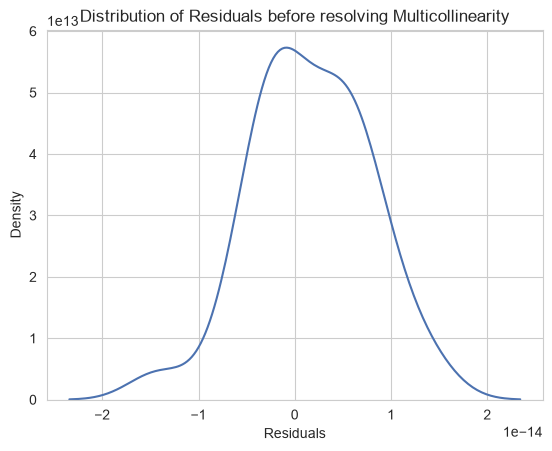

In [14]:
sns.kdeplot(x=slr1.residuals)
plt.title("Distribution of Residuals before resolving Multicollinearity")
plt.xlabel("Residuals")

plt.show()

##### Remove multicollinearity from dataset

In [15]:
smp_nmc_df = resolve_multicollinearity(df=smp_df.drop(columns="Target"), vif_threshold=5)
smp_nmc_df["Target"] = smp_df["Target"]


------------------------------------------------------
Calculating VIF to check Multicollinearity in dataset.

VIF ledger:


,Feature,VIF
0,Feature 2,20.402356
1,Feature 5,20.388908
2,Feature 4,16.335035
3,Feature 1,16.287665
4,Feature 3,12.990807
5,Feature 6,12.982226
6,const,1.000000


Dropping feature: 'Feature 2' with VIF value: 20.40
------------------------------------------------------


------------------------------------------------------
Calculating VIF to check Multicollinearity in dataset.

VIF ledger:


,Feature,VIF
0,Feature 1,16.138084
1,Feature 4,16.135174
2,Feature 6,12.874049
3,Feature 3,12.804167
4,Feature 5,1.015664
5,const,1.000000


Dropping feature: 'Feature 1' with VIF value: 16.14
------------------------------------------------------


------------------------------------------------------
Calculating VIF to check Multicollinearity in dataset.

VIF ledger:


,Feature,VIF
0,Feature 6,12.781605
1,Feature 3,12.687600
2,Feature 4,1.021547
3,Feature 5,1.014149
4,const,1.000000


Dropping feature: 'Feature 6' with VIF value: 12.78
------------------------------------------------------


------------------------------------------------------
Calculating VIF to check Multicollinearity in dataset.

VIF ledger:


,Feature,VIF
0,Feature 3,1.019936
1,Feature 4,1.016605
2,Feature 5,1.007016
3,const,1.000000


------------------------------------------------------


Stopping Multicollinearity check. Dataset has no Multicollinearity.



##### VIF

In [16]:
get_vif_ledger(df=smp_nmc_df.drop(columns="Target"))

,Feature,VIF
0,Feature 3,1.019936
1,Feature 4,1.016605
2,Feature 5,1.007016
3,const,1.000000


In [17]:
slr2 = SimpleLinearRegression(df=smp_nmc_df, target="Target")
slr2.print_report()


Linear Regression Results

Coefficients
------------
+-----------+-------------+
| Feature   | Coefficient |
+-----------+-------------+
| Feature 3 |   -6.751275 |
| Feature 4 |    5.154389 |
| Feature 5 |    8.841806 |
+-----------+-------------+

R-squared
---------
Training R-squared: 0.959871
Testing R-squared: 0.960048


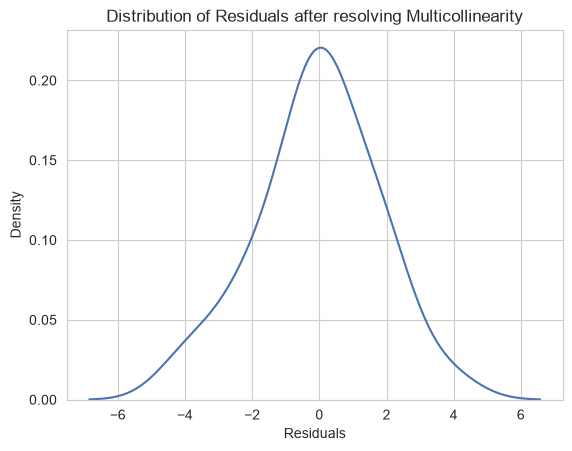

In [18]:
sns.kdeplot(x=slr2.residuals)
plt.title("Distribution of Residuals after resolving Multicollinearity")
plt.xlabel("Residuals")

plt.show()

## 4 No Heteroscedasticity

### 4.1 Introduction

#### What is Heteroscedasticity?

- Homoscedasticity checks whether the residual variance remains constant across the predicted values.
- Opposite of Heteroscedasticity is Homoscedasticity.
- The desired nature is Homoscedasticity or No Heteroscedasticity.

### 4.2 Tests for Heteroscedasticity

#### Analytical Tests

1. Goldfeld-Quandt Test

#### Graphical Tests

1. Scatter Plot

### 4.3 Examples

#### Graphical Tests

##### Scatter plot

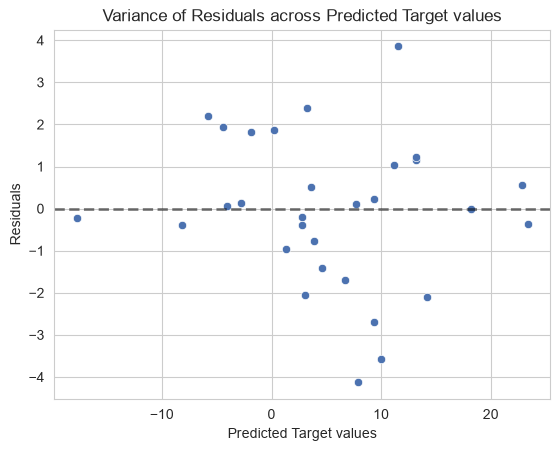

In [19]:
ax = sns.scatterplot(x=slr2.y_pred, y=slr2.residuals)
ax.axhline(y=0, color="k", alpha=0.5, linestyle="--", linewidth=2)
plt.title("Variance of Residuals across Predicted Target values")
plt.xlabel("Predicted Target values")
plt.ylabel("Residuals")

plt.show()

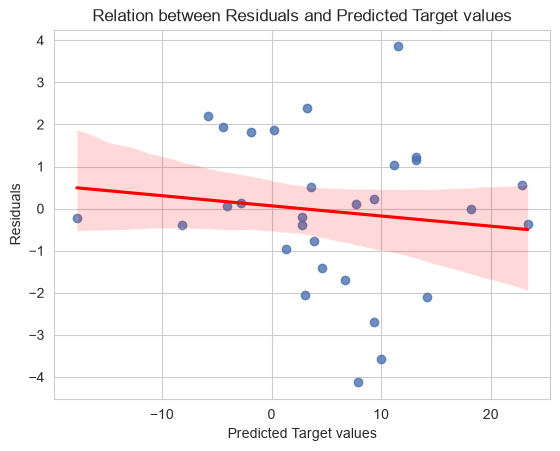

In [20]:
sns.regplot(x=slr2.y_pred, y=slr2.residuals, line_kws={"color": "red"})
plt.title("Relation between Residuals and Predicted Target values")
plt.xlabel("Predicted Target values")
plt.ylabel("Residuals")

plt.show()

## 5 No Autocorrelation

### 5.1 Introduction

#### What is Autocorrelation?

- Correlation is a measure of relationship between two continuous variables.
- Pearson Correlation Coefficient ranges between $[-1,\,+1]$
- Correlation represents some degree of similarity.
- Autocorrelation is the correlation between a variable and a lagged version of itself over successive time intervals or spatial distance.
- Desired nature is no Autocorrelation between Residuals and Actual Target values.

### 5.2 Tests for No Autocorrelation

#### Analytical Tests

1. Durbin-Watson test

#### Graphical Tests

1. Scatter Plot

### 5.3 Examples

#### Graphical Tests

##### Scatter plot

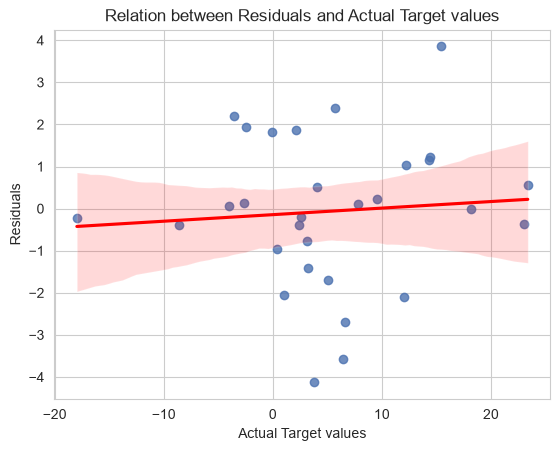

In [21]:
sns.regplot(x=slr2.y_test, y=slr2.residuals, line_kws={"color": "red"})
plt.title("Relation between Residuals and Actual Target values")
plt.xlabel("Actual Target values")
plt.ylabel("Residuals")

plt.show()

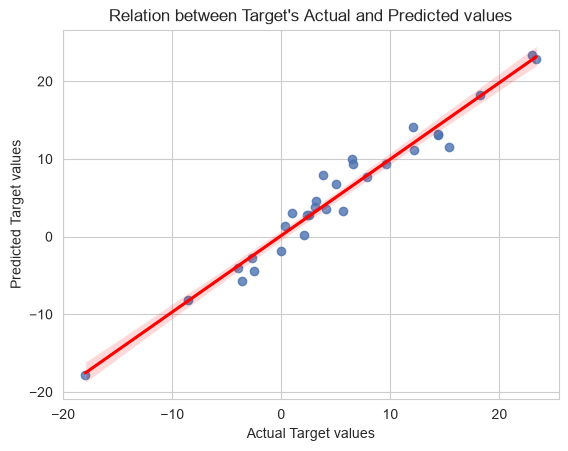

In [22]:
sns.regplot(x=slr2.y_test, y=slr2.y_pred, line_kws={"color": "red"})
plt.title("Relation between Target's Actual and Predicted values")
plt.xlabel("Actual Target values")
plt.ylabel("Predicted Target values")

plt.show()

## 6 Normality of Residuals

### 6.1 Introduction

#### What is Normality of Residuals?

- Residuals (errors) must follow Normal distribution.
- If Residuals are Normal that indicates the **errors are truely random**.

### 6.2 Tests for Normality of Residuals

#### Analytical Tests

1. Kolmogorov-Smirnov Test
2. Shapiro-Wilk Test

#### Graphical Tests

1. Distribution Plot (Histogram)
2. Quantile-Quantile Plot

### 6.3 Example

In [23]:
print("Mean of residuals:", slr2.residuals.mean().round(6).item())

Mean of residuals: -0.062447


#### Graphical Tests

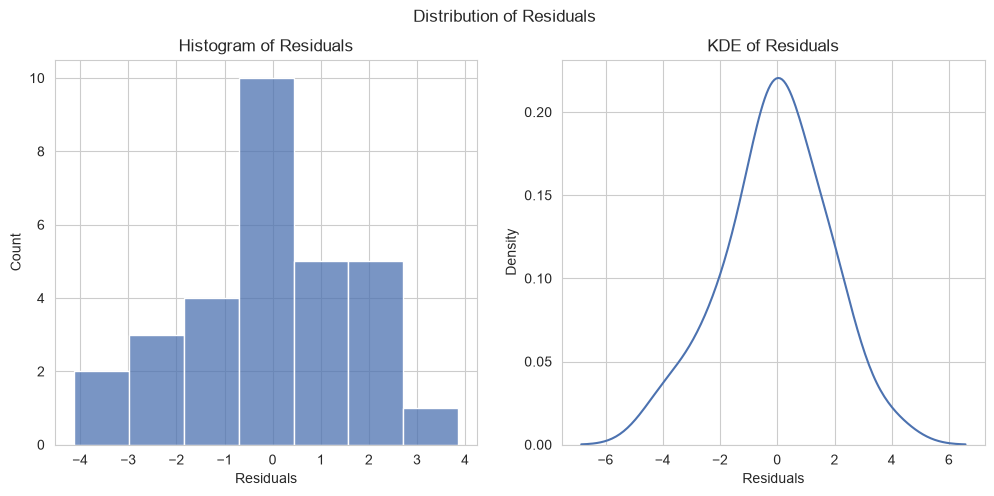

In [24]:
plt.figure(figsize=(12, 5))
plt.suptitle("Distribution of Residuals")

plt.subplot(1, 2, 1)
sns.histplot(x=slr2.residuals)
plt.title("Histogram of Residuals")
plt.xlabel("Residuals")

plt.subplot(1, 2, 2)
sns.kdeplot(x=slr2.residuals)
plt.title("KDE of Residuals")
plt.xlabel("Residuals")

plt.show()